In [ ]:
import pandas as pd
import numpy as np


def cited_probability(c1, c2):
    c1.name = "c1"
    c2.name = "c2"
    total_new_cites = c2.sum() - c1.sum()
    probability = (c2 - c1) / total_new_cites
    probability.name = "probability"
    df = pd.concat([c1,c2, probability], axis=1)
    
    pi = df.groupby('c1')['probability'].mean()
    return pi


In [11]:
openalex_df = pd.read_pickle("data/biorxiv/biorxiv_openalex.pkl")
openalex_df["doi"] = openalex_df['doi'].str.replace("https://doi.org/", "")
openalex_df.head()

/tmp/ipykernel_1630305/1171487735.py:2: FutureWarning: The default value of regex will change from True to False in a future version.
  openalex_df["doi"] = openalex_df['doi'].str.replace("https://doi.org/", "")


,id,counts_by_year,publication_year,publication_date,authorships,primary_topic,cited_by_count,doi,locations,locations_count
0,https://openalex.org/W3202105508,"[{'year': 2025, 'cited_by_count': 68}, {'year'...",2021,2021-10-04,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10044', 'display...",2744,10.1101/2021.10.04.463034,"[{'is_oa': True, 'landing_page_url': 'https://...",1
1,https://openalex.org/W3099862724,"[{'year': 2025, 'cited_by_count': 39}, {'year'...",2016,2016-06-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10887', 'display...",2527,10.1101/060012,"[{'is_oa': True, 'landing_page_url': 'https://...",1
2,https://openalex.org/W2770095154,"[{'year': 2025, 'cited_by_count': 21}, {'year'...",2017,2017-11-14,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1589,10.1101/201178,"[{'is_oa': True, 'landing_page_url': 'https://...",1
3,https://openalex.org/W2538509698,"[{'year': 2024, 'cited_by_count': 258}, {'year...",2016,2016-10-15,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1568,10.1101/081257,"[{'is_oa': True, 'landing_page_url': 'https://...",1
4,https://openalex.org/W2952535963,"[{'year': 2024, 'cited_by_count': 87}, {'year'...",2014,2014-02-20,"[{'author_position': 'first', 'author': {'id':...","{'id': 'https://openalex.org/T10015', 'display...",1382,10.1101/002824,"[{'is_oa': True, 'landing_page_url': 'https://...",2


In [8]:
biorxiv_df = pd.concat([
    pd.read_json(f"data/biorxiv/full_{year}.jsonl", lines=True)
    for year in range(2021, 2025)
])

In [12]:
pub = openalex_df[openalex_df["doi"].isin(biorxiv_df[~biorxiv_df["published"].isna()]["doi"])]
nopub = openalex_df[openalex_df["doi"].isin(biorxiv_df[biorxiv_df["published"].isna()]["doi"])]

In [14]:
def oldest_year(counts_by_year):
    l = [d['year'] for d in counts_by_year]
    if len(l)==0:
        return 0
    else:
        return min(l)

print(pub.shape[0])
pub = pub[pub["publication_year"]<=pub["counts_by_year"].apply(oldest_year)]
nopub = nopub[nopub["publication_year"]<=nopub["counts_by_year"].apply(oldest_year)]

pub.shape[0]

70577


36147

In [15]:
from collections import defaultdict

def yearly(counts_by_year):
    years = range(2012, 2025)
    counts_dict = {d['year']: d['cited_by_count'] for d in counts_by_year}
    
    default_value = None 
    completed = defaultdict()
    for year in years:
        if year in counts_dict:
            completed[year] = counts_dict[year]
            default_value = 0
        else:
            completed[year] = default_value
        
    return completed
# yearly_oa = oa_["counts_by_year"].apply(yearly).apply(pd.Series).dropna(subset=[2022, 2023])
yearly_pub = pub["counts_by_year"].apply(yearly).apply(pd.Series).dropna(subset=[2022, 2023])
yearly_nopub = nopub["counts_by_year"].apply(yearly).apply(pd.Series).dropna(subset=[2022, 2023])

yearly_pub_cum = yearly_pub.cumsum(axis=1)
yearly_nopub_cum = yearly_nopub.cumsum(axis=1)
yearly_nopub_cum.head()

,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
1,NaN,NaN,NaN,NaN,1.0,4.0,36.0,133.0,336.0,750.0,1182.0,1780.0,2487.0
11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69.0,359.0,784.0
52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,245.0,296.0,312.0,320.0
66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,134.0,248.0,273.0,279.0
67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.0,75.0,155.0,271.0


In [16]:
from matplotlib import pyplot as plt
import numpy as np
import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
plt.rc('axes', titlesize=15, labelsize=15)      # Title font size
plt.rc('xtick', labelsize=12)     # X-axis tick font size
plt.rc('ytick', labelsize=12)     # Y-axis tick font size
plt.rc('legend', fontsize=13)     # Legend font sizplt

print(plt.rcParams['axes.prop_cycle'].by_key()['color'])

['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


In [17]:
import pandas as pd
cited_by_count_c4 = pd.read_pickle("/disks/qnap3/shared/scopus-24/data/paper/num_cited_c4.pickle").rename_axis(index = "eid")
cited_by_count_c5 = pd.read_pickle("/disks/qnap3/shared/scopus-24/data/paper/num_cited_c5.pickle").rename_axis(index = "eid")
pub_year = pd.read_pickle("/disks/qnap3/shared/scopus-24/data/paper/year.pickle").rename_axis(index = "eid")

cited_by_count = pd.DataFrame(pub_year[pub_year==2015]).rename_axis(index="eid").merge(
    cited_by_count_c4,
    on='eid'
).merge(
    cited_by_count_c5,
    on='eid'
)
cited_by_count["growth"] = cited_by_count["c5"] - cited_by_count["c4"]
cited_by_count.head()

,year,c4,c5,growth
eid,,,,
44649191932,2015,1.0,1.0,0.0
80053392109,2015,2.0,2.0,0.0
84855602171,2015,9.0,10.0,1.0
84856394442,2015,5.0,7.0,2.0
84856569921,2015,6.0,10.0,4.0


['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


Text(0.5, 1.0, 'Preprint')

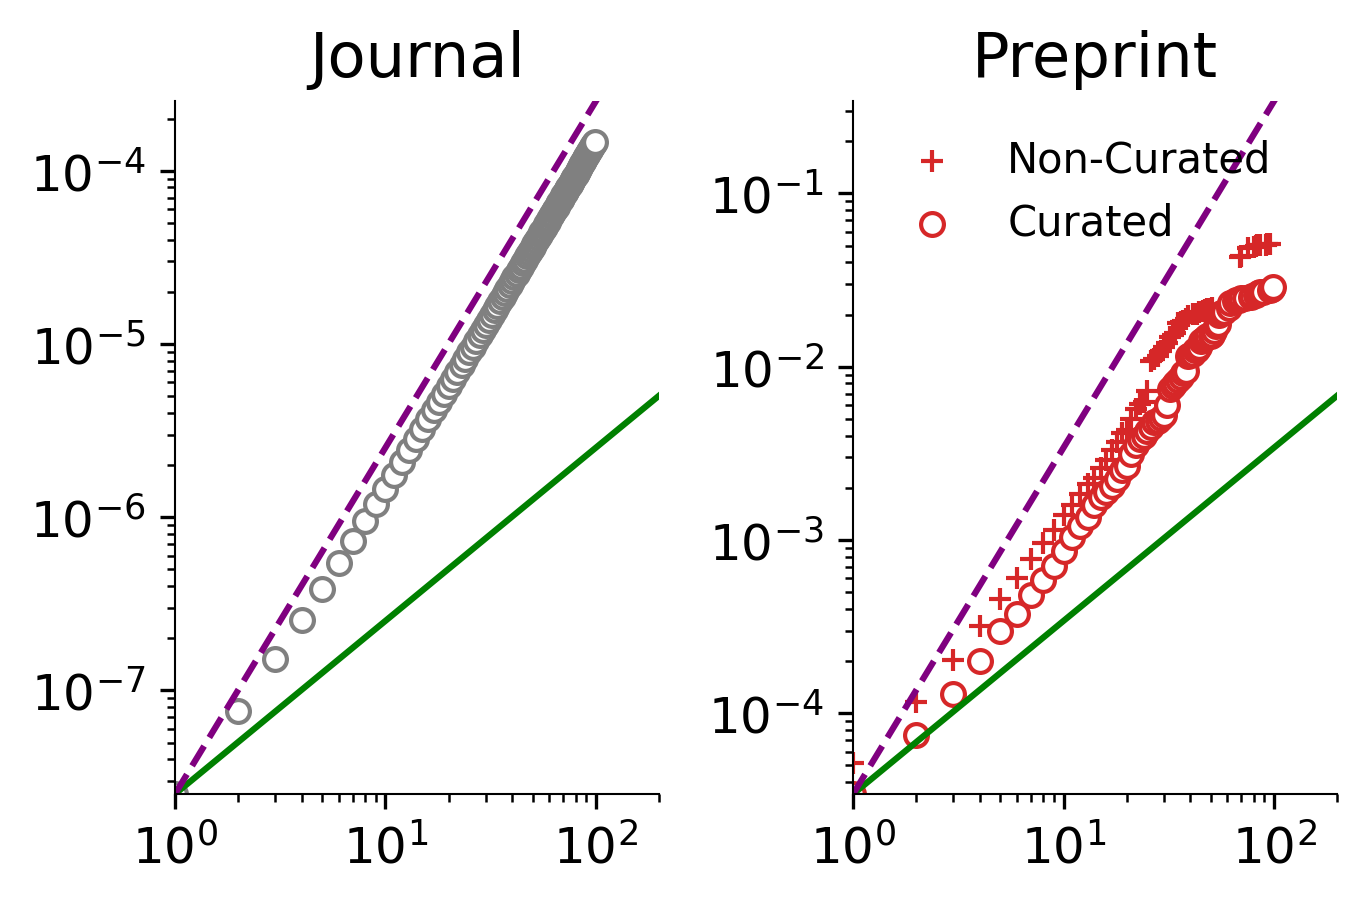

In [49]:
pi_p = cited_probability(yearly_pub_cum[2022], yearly_pub_cum[2023])
pi_n = cited_probability(yearly_nopub_cum[2022], yearly_nopub_cum[2023])
pi_j = cited_probability(cited_by_count["c5"], cited_by_count["c4"])

print(plt.rcParams['axes.prop_cycle'].by_key()['color'])
fig, ax = plt.subplots(1,2, figsize=(5,3))
fig.subplots_adjust(hspace=0.1, wspace=0.4)

def plot_citation_probability(ax, pi, **kwargs):
    ax.spines[['right', 'top']].set_visible(False)
    ax.tick_params(which='both', top=False, right=False)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1, 2e+2)

    pi = pi[pi.index > 0]
    scale = pi.loc[1]

    x = np.linspace(1, 10**4, 10**4)
    if kwargs.get('multi', None) is None:
        ax.plot(x, x * scale, linestyle="-", color="green", linewidth=1.5)
        ax.plot(x, np.square(x) * scale, linestyle="--", color="purple", linewidth=1.5)
        ax.set_ylim(pi.loc[1], pi.loc[1]* 10**4)
        # ax.plot(x, [scale] *10**3, linestyle="-", color="gray")
        # ax.plot(x, x * scale*10, linestyle="--", color="green")
        # ax.set_ylim(scale/10, scale* 10**5)

    kwargs.pop('multi', None)
    pi = pi[pi.index < 10**2]
    ax.scatter(pi.index, pi.values.cumsum(), s=30, **kwargs)
    # ax.scatter(pi.index, pi.values, s=30, **kwargs)


    

plot_citation_probability(ax[0], pi_j, edgecolors="grey", color="white", marker = "o")
plot_citation_probability(ax[1], pi_n, color=plt.rcParams['axes.prop_cycle'].by_key()['color'][3], label="Non-Curated", marker = "+", multi=True)
plot_citation_probability(ax[1], pi_p, edgecolor=plt.rcParams['axes.prop_cycle'].by_key()['color'][3], color="white", label="Curated", marker = "o")
ax[0].set_title("Journal")
ax[1].legend(loc="upper left", fontsize=10, frameon=False)
ax[1].set_title("Preprint")